In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.signal import butter, filtfilt
import pickle
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import seaborn as sns

Call in WESAD EDA data from `load_eda.ipnyb` and conducts Buttersworth low-pass on participant's EDA signals. Final dataframe produced ``

- normal_flag = 1: normalization applied
- normal_flag = 0: not applied

In [ ]:
normal_flag = 1 # or 0

In [4]:
with open("../Data/wesad_eda/wesad_subject_list.pkl", "rb") as f:
    wesad_data = pickle.load(f)
wesad_data[0]

,S15_EDA,S15_Label
0,0.220298,0
1,0.170407,0
2,0.189596,0
3,0.151218,0
4,0.166569,0
...,...,...
21003,0.454401,0
21004,0.455680,0
21005,0.454401,0
21006,0.451842,0


The raw EDA signal as a baseline of S15

Text(0.5, 1.0, 'S15 EDA Signal Over Time')

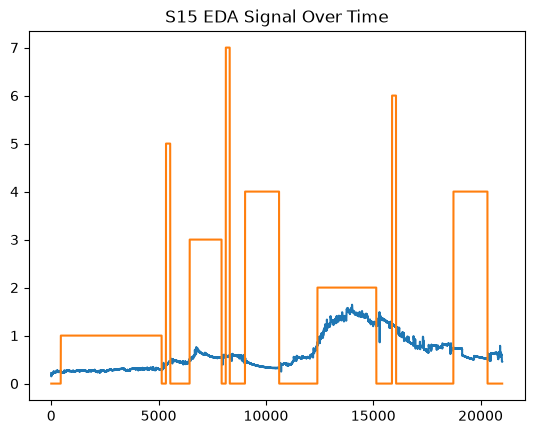

In [5]:
plt.plot(wesad_data[0])
plt.title("S15 EDA Signal Over Time")

Buttersworth filter applied to one signal, S15
Parameter choice is based on Nyquist-Shannon sampling theorem, cut off was decided following Hosseini paper

In [7]:
#Extract out Partcipant 15's EDA signal for processing
s15 = wesad_data[0]
s15_eda = s15.iloc[:,0]
#Parameters for Buttersworth filter
#Frequency sampling rate
fs = 4.0
#Frequency Cutoff, conservative, most SCR lives below 0.5 but phasic features tend to live in 1-1.5 land and Nyquist means we have to keep threshold below 2 so conservative cleaning
fc = 1.5
#Cutoff rate rationalized for nyquist
cutoff = (2*fc)/fs          
#Creates the denominator and numerator for the filtering of the signal in the Buttersworth transfer function, low-pass filter
b, a = butter(4, cutoff, btype='low')
# Apply filter onto participant 15
s15_filtered = filtfilt(b, a, s15_eda)

Text(0, 0.5, 'EDA (µS)')

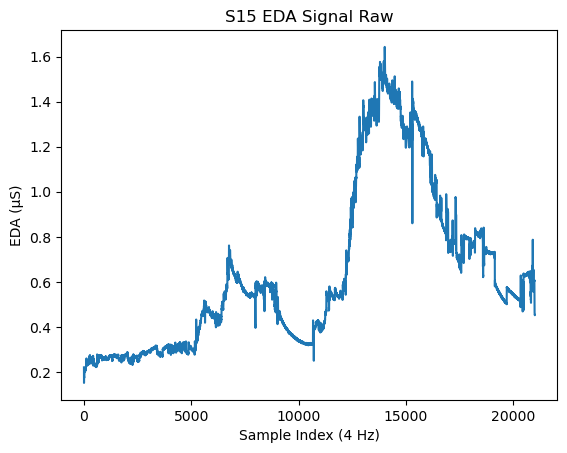

In [76]:
plt.plot(s15_eda)
plt.title("S15 EDA Signal Raw")
plt.xlabel("Sample Index (4 Hz)")
plt.ylabel("EDA (µS)")

Text(0, 0.5, 'EDA (µS)')

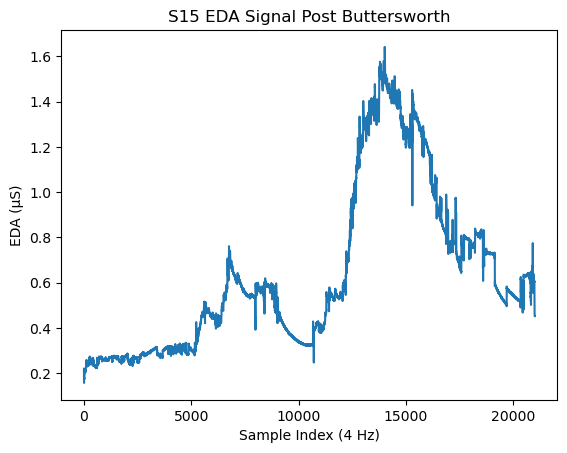

In [125]:
# 4. Plot original vs filtered signal
plt.plot(s15_filtered)
plt.title("S15 EDA Signal Post Buttersworth")
plt.xlabel("Sample Index (4 Hz)")
plt.ylabel("EDA (µS)")

In [127]:
np.abs(s15_eda - s15_filtered).sum()

22.94471742740315

Loop through all EDA signals to apply Buttersworth filter and per subject min-max normalization and create a dataframe

In [ ]:
filtered_signals = []


for i in range(len(wesad_data)):
    participant_data = wesad_data[i]
    participant_signal = participant_data.iloc[:, 0]
    
    # Butterworth filter applied
    sos = signal.butter(N=4, Wn=cutoff, btype='low', output='sos', fs=4)
    participant_filtered = signal.sosfilt(sos, participant_signal)
    
    #Apply normaliziation, reshape with a column for row ID then flatten back down to only the original signal
    if normal_flag == 1:
        participant_filtered = MinMaxScaler().fit_transform(participant_filtered.reshape(-1, 1)).ravel()
    
    # Build dataframe and append
    subject_id = participant_data.columns[0].split('_')[0]
    filtered_dataframe = pd.DataFrame({
        f'{subject_id}_EDA': participant_filtered,
        f'{subject_id}_Label': participant_data.iloc[:, 1]
    })
    filtered_signals.append(filtered_dataframe)

Combine all dataframes into onem remove NAs based on the shortest signal, to convert to a pickle for future processing

In [9]:
filtered_eda = pd.concat(filtered_signals, axis=1)
filtered_eda_na_omitted = filtered_eda.dropna()
filtered_eda_na_omitted

,S15_EDA,S15_Label,S7_EDA,S7_Label,S3_EDA,S3_Label,S2_EDA,S2_Label,S14_EDA,S14_Label,...,S4_EDA,S4_Label,S13_EDA,S13_Label,S5_EDA,S5_Label,S9_EDA,S9_Label,S6_EDA,S6_Label
0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,...,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0
1,0.024334,0.0,0.140501,0.0,0.050676,0.0,0.128713,0.0,0.053861,0.0,...,0.010195,0.0,0.110283,0.0,0.021336,0.0,0.035336,0.0,0.053788,0
2,0.070629,0.0,0.426794,0.0,0.158537,0.0,0.385883,0.0,0.158827,0.0,...,0.030701,0.0,0.330945,0.0,0.063259,0.0,0.106946,0.0,0.162680,0
3,0.112352,0.0,0.718655,0.0,0.275980,0.0,0.634077,0.0,0.252688,0.0,...,0.051106,0.0,0.548420,0.0,0.103415,0.0,0.179713,0.0,0.272176,0
4,0.122235,0.0,0.841354,0.0,0.335076,0.0,0.712808,0.0,0.267634,0.0,...,0.058771,0.0,0.630132,0.0,0.115721,0.0,0.210381,0.0,0.315569,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20887,0.372521,0.0,0.555678,0.0,0.035789,3.0,0.077091,0.0,0.316861,4.0,...,0.075557,0.0,0.336906,4.0,0.236026,0.0,0.278295,0.0,0.136655,0
20888,0.378905,0.0,0.554496,0.0,0.035763,3.0,0.074389,0.0,0.316615,4.0,...,0.075649,0.0,0.336961,4.0,0.235968,0.0,0.277387,0.0,0.136465,0
20889,0.391190,0.0,0.553613,0.0,0.035742,3.0,0.069663,0.0,0.315819,4.0,...,0.075410,0.0,0.336977,4.0,0.235923,0.0,0.276321,0.0,0.136276,0
20890,0.402931,0.0,0.553556,0.0,0.035748,3.0,0.067496,0.0,0.315374,4.0,...,0.075067,0.0,0.336969,4.0,0.235948,0.0,0.275335,0.0,0.136126,0


In [10]:
filtered_eda_na_omitted.to_csv("../Data/wesad_eda/filtered_eda_signals.csv", index=False)

Checking visually why they end at different activity label markers, time_scale appears to be relatively similar but slight cut off at the end, unsure if it is a complete problem

Text(0.5, 1.0, 'S15 EDA Signal Post Buttersworth NA Omitted')

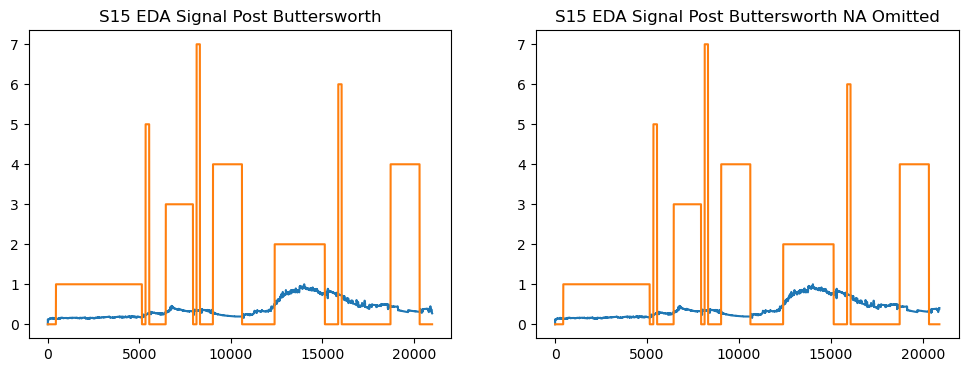

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(filtered_eda.iloc[:,0])
ax1.plot(filtered_eda.iloc[:,1])
ax1.set_title("S15 EDA Signal Post Buttersworth")
ax2.plot(filtered_eda_na_omitted.iloc[:,0])
ax2.plot(filtered_eda_na_omitted.iloc[:,1])
ax2.set_title("S15 EDA Signal Post Buttersworth NA Omitted")